# DATA 201 Project 1 — Bank Marketing Classification


In [1]:
#Project 1 - Classification Practice (Supervised Machine Learning - Classification)
#Option C- Product Subcription Status Classification
#Evan Xing

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
# Optional in Google Colab: from google.colab import drive
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis, LinearDiscriminantAnalysis
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

In [2]:
# Dataset loading

path = Path('bank-full.csv')
raw = pd.read_csv(path, sep=";")

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


(45211, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


None

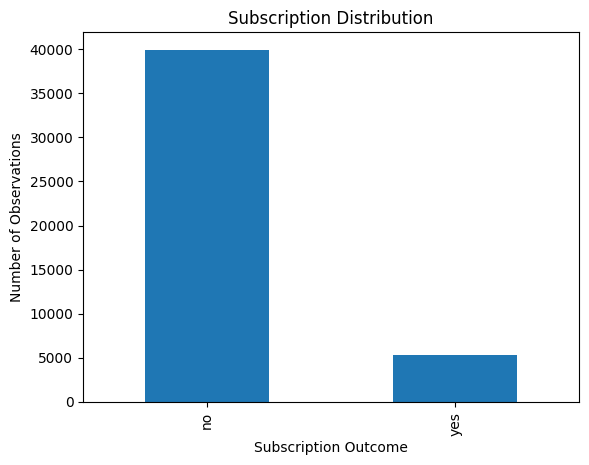

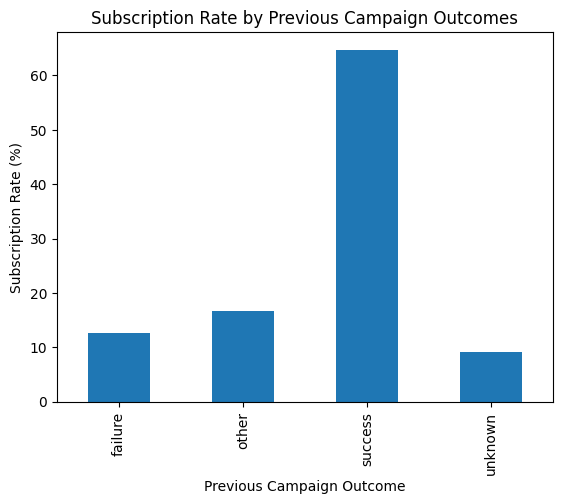

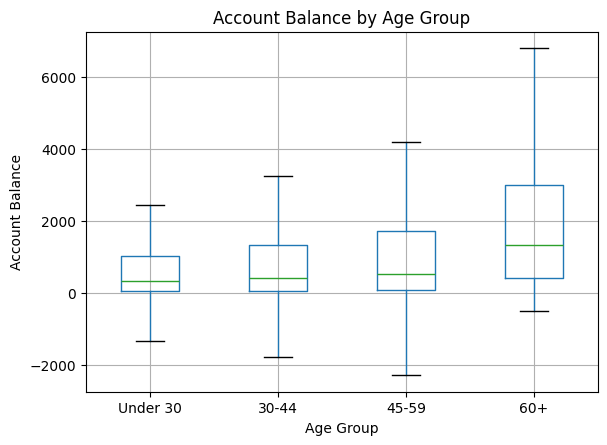

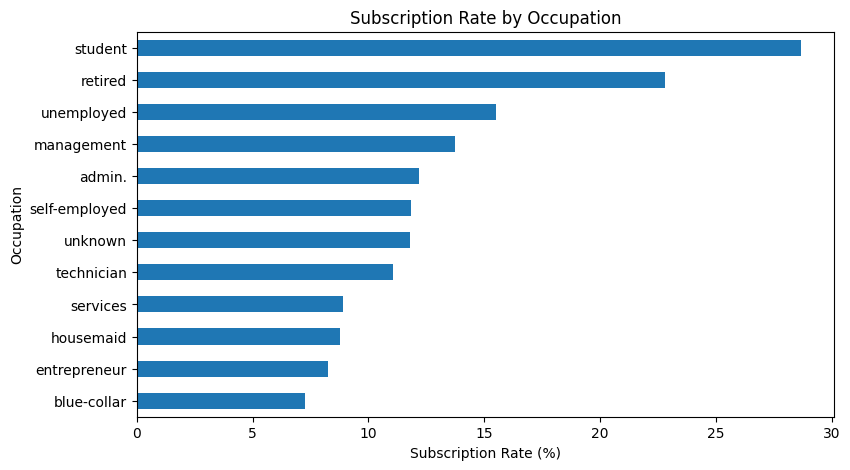

In [3]:
#Datset Cleaning, feature Engineering, and EDA

#Dataset Cleaning

cleaned_raw = raw.dropna() # Removes all na rows. There are none.
cleaned_raw.duplicated().sum() # No duplicated rows present.


#EDA & Feature Engineering
display(cleaned_raw.describe()) # summary statistics
print(cleaned_raw.shape) # structure
display(cleaned_raw.info()) # dataset info for variables

# Class counts for the response variable plotted as a bar chart
cleaned_raw['y'].value_counts().plot(kind='bar')

plt.title('Subscription Distribution')
plt.xlabel('Subscription Outcome')
plt.ylabel('Number of Observations')
plt.show()


# Convert y in to a new feature column in the cleaned dataframe called subscription with outcomes to 1 (yes) or 0 (no)
cleaned_raw['subscribed'] = (cleaned_raw['y'] == 'yes').astype(int)

# Calculate subscription rate for each previous campaign outcome
rates = cleaned_raw.groupby('poutcome')['subscribed'].mean() * 100

# Create the bar chart
rates.plot(kind='bar')

plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Subscription Rate (%)')
plt.title('Subscription Rate by Previous Campaign Outcomes')
plt.show()



#Binning of age column into a new feature column age_group using pd.cut

cleaned_raw['age_group'] = pd.cut(
    cleaned_raw['age'],
    bins=[0, 30, 45, 60, 100],
    labels=['Under 30', '30-44', '45-59', '60+']
)

# Displays a boxplot with x as age groups and y as balance; outliers disabled from being displayed
cleaned_raw.boxplot(
    column='balance',
    by='age_group',
    showfliers=False,
)

plt.title('Account Balance by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Account Balance')
plt.suptitle('')
plt.show()




#Displays a horizontal barchart with subscription rate by occupation

cleaned_raw['subscribed'] = (cleaned_raw['y'] == 'yes').astype(int)

rates = cleaned_raw.groupby('job')['subscribed'].mean() * 100

rates.sort_values().plot(kind='barh', figsize=(9, 5))

plt.title('Subscription Rate by Occupation')
plt.xlabel('Subscription Rate (%)')
plt.ylabel('Occupation')
plt.show()

#Added a new days_since_contact column since pdays would not scale appropriately with standard scaler; Though I ended up opting to just use previous instead
cleaned_raw['previously_contacted'] = (cleaned_raw['pdays'] != -1).astype(int)
# 1 = contacted previously and 0 means no prior contact
cleaned_raw['days_since_contact'] = (cleaned_raw['pdays'].replace(-1, 0))
#days_since_contact = number of days since last contact with 0 meaning no prior contact

Cross-validation F1 scores: [0.28230616 0.25254582 0.24144869 0.2778865  0.31952663 0.29615385
 0.28849903 0.2125     0.28070175 0.244     ]
Mean CV F1: 0.26955684301864924
CV standard deviation: 0.029845270933671675
Confusion Matrix:
[[9867  114]
 [1076  246]]
Accuracy: 0.894718216402725
Precision: 0.6833333333333333
Recall: 0.18608169440242056
F1 Score: 0.2925089179548157
ROC-AUC: 0.7733697429048626


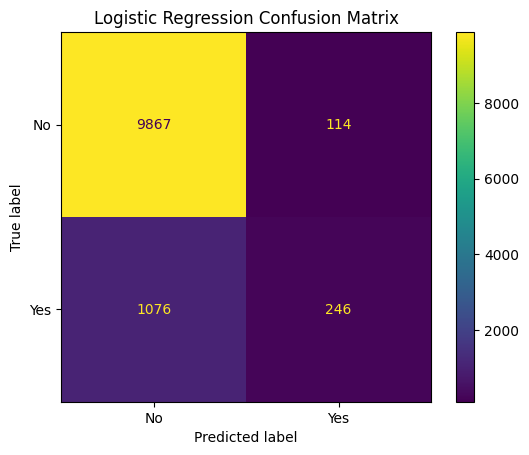

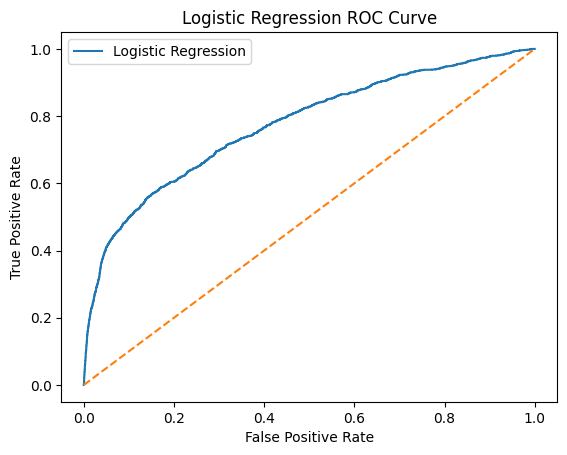

In [4]:
#Models

#Logisitcal Regression - default threshold .5

numeric_cols = ['age', 'balance', 'campaign', 'previous','days_since_contact']
categorical_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

x = cleaned_raw[numeric_cols + categorical_cols]
y = (cleaned_raw['y'] == 'yes').astype(int)

#spliting the data <-- used for all other models

X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

#encoding and scaling done with columnTransformer for all categorical and numeic cols
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

#Pipeline
logreg = make_pipeline(
    preprocessor,
    LogisticRegression(max_iter=2000)
)
# 10 k folds cv
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Cv_scores using f1 scoring; balances precision and recall
cv_scores = cross_val_score(
    logreg,
    X_train,
    y_train,
    cv=cv,
    scoring='f1'
)
# CV scores
print("Cross-validation F1 scores:", cv_scores)
print("Mean CV F1:", cv_scores.mean())
print("CV standard deviation:", cv_scores.std())


# Fit model using the entire training set

logreg.fit(X_train, y_train)

# Predict test set outcomes

y_pred = logreg.predict(X_test)

# Predicted probabilities for subscription

y_prob = logreg.predict_proba(X_test)[:, 1]

# Evaluate test performance

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

# Plot confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['No', 'Yes']
)

plt.title('Logistic Regression Confusion Matrix')
plt.show()

# Plot ROC curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Logistic Regression ROC Curve')
plt.legend()
plt.show()

LDA Cross-validation F1 scores: [0.37333333 0.34829443 0.29411765 0.34825871 0.41322314 0.37987013
 0.3803056  0.34662045 0.35489221 0.36115843]
LDA Mean CV F1: 0.360007408336641
LDA CV standard deviation: 0.02939290052839052
Confusion Matrix:
[[9701  280]
 [ 931  391]]
Accuracy: 0.8928603025745377
Precision: 0.5827123695976155
Recall: 0.2957639939485628
F1: 0.3923733065730055
ROC-AUC: 0.7701779750663933


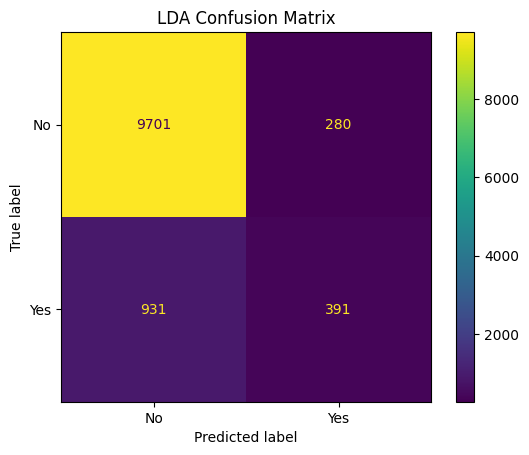

In [5]:
#LDA default threshold at .5

# Redo Preprocessor for LDA, drops first column to help prevent redundancies and linear dependency and thus multicollinearity which violates LDA normality assumptions
lda_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False,
        drop = 'first'
    ), categorical_cols)
])

# Make new pipeline for lda
lda = make_pipeline(
    lda_preprocessor,
    LinearDiscriminantAnalysis()
)
# LDA cv scores
lda_cv_scores = cross_val_score(
    lda,
    X_train,
    y_train,
    cv=cv,
    scoring='f1'
)

print("LDA Cross-validation F1 scores:", lda_cv_scores)
print("LDA Mean CV F1:", lda_cv_scores.mean())
print("LDA CV standard deviation:", lda_cv_scores.std())

# Train LDA model

lda.fit(X_train, y_train)

# Predict test outcomes

lda_pred = lda.predict(X_test)
lda_prob = lda.predict_proba(X_test)[:, 1]

# Evaluate performance

print("Confusion Matrix:")
print(confusion_matrix(y_test, lda_pred))

print("Accuracy:", accuracy_score(y_test, lda_pred))
print("Precision:", precision_score(y_test, lda_pred))
print("Recall:", recall_score(y_test, lda_pred))
print("F1:", f1_score(y_test, lda_pred))
print("ROC-AUC:", roc_auc_score(y_test, lda_prob))

# Plot confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lda_pred,
    display_labels=['No', 'Yes']
)

plt.title('LDA Confusion Matrix')
plt.show()

In [6]:
#QDA default threshold at .5

# Preprocessing for QDA
qda_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse_output=False
    ), categorical_cols)
])

# Create QDA model
qda = make_pipeline(
    qda_preprocessor,
    QuadraticDiscriminantAnalysis(reg_param=0.1)
)

# 10-fold cross-validation
qda_cv_scores = cross_val_score(
    qda, X_train, y_train, cv=cv, scoring='f1'
)

print("QDA Cross-validation F1 scores:", qda_cv_scores)
print("QDA Mean CV F1:", qda_cv_scores.mean())
print("QDA CV standard deviation:", qda_cv_scores.std())

# Train QDA model
qda.fit(X_train, y_train)

# Predictions
qda_pred = qda.predict(X_test)
qda_prob = qda.predict_proba(X_test)[:, 1]

# Evaluation
print("Confusion Matrix:")
print(confusion_matrix(y_test, qda_pred))

print("Accuracy:", accuracy_score(y_test, qda_pred))
print("Precision:", precision_score(y_test, qda_pred))
print("Recall:", recall_score(y_test, qda_pred))
print("F1:", f1_score(y_test, qda_pred))
print("ROC-AUC:", roc_auc_score(y_test, qda_prob))

QDA Cross-validation F1 scores: [0.34730539 0.33597464 0.31796502 0.37237237 0.39939024 0.40059347
 0.38846737 0.31347962 0.38729198 0.35680751]
QDA Mean CV F1: 0.36196476367945196
QDA CV standard deviation: 0.030901108568047994
Confusion Matrix:
[[9565  416]
 [ 915  407]]
Accuracy: 0.8822436521277537
Precision: 0.4945321992709599
Recall: 0.30786686838124055
F1: 0.37948717948717947
ROC-AUC: 0.7630409654288685


Best K: 3
Best Mean CV F1: 0.29673518834412543


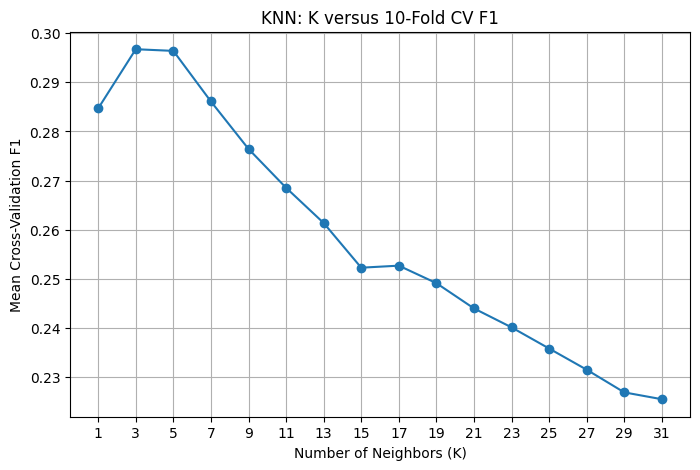

KNN Cross-validation F1 scores: [0.23728814 0.3026087  0.28338762 0.31290323 0.32206119 0.35218094
 0.31788079 0.27054795 0.28802589 0.28046745]
KNN Mean CV F1: 0.29673518834412543
KNN CV standard deviation: 0.030326638970189793

Confusion Matrix:
[[9614  367]
 [ 987  335]]
Accuracy: 0.8802087941254534
Precision: 0.4772079772079772
Recall: 0.2534039334341906
Specificity: 0.9632301372607955
F1: 0.3310276679841897
ROC-AUC: 0.6731534620771902


In [7]:
#KNN - default threshold .5

#Preprocessor
knn_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore'
    ), categorical_cols)
])

# Select K from 1-32 at increments of 2.
k_values = list(range(1, 32, 2))
mean_f1_scores = []

for k in k_values:
    candidate_knn = make_pipeline(
        knn_preprocessor,
        KNeighborsClassifier(n_neighbors=k)
    )
    k_scores = cross_val_score(candidate_knn, X_train, y_train, cv=cv, scoring='f1')
    mean_f1_scores.append(k_scores.mean())

best_index = mean_f1_scores.index(max(mean_f1_scores))
best_k = k_values[best_index]
print('Best K:', best_k)
print('Best Mean CV F1:', mean_f1_scores[best_index])

plt.figure(figsize=(8, 5))
plt.plot(k_values, mean_f1_scores, marker='o')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Mean Cross-Validation F1')
plt.title('KNN: K versus 10-Fold CV F1')
plt.xticks(k_values)
plt.grid(True)
plt.show()

knn = make_pipeline(knn_preprocessor, KNeighborsClassifier(n_neighbors=best_k))
scores = cross_val_score(knn, X_train, y_train, cv=cv, scoring='f1')

# Display cross-validation results
print("KNN Cross-validation F1 scores:", scores)
print("KNN Mean CV F1:", scores.mean())
print("KNN CV standard deviation:", scores.std())

# Fit the model using the full training dataset
knn.fit(X_train, y_train)

# Predict target classes and probabilities on test data
knn_pred = knn.predict(X_test)
knn_prob = knn.predict_proba(X_test)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_test, knn_pred)
print("\nConfusion Matrix:")
print(cm)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, knn_pred)
precision = precision_score(y_test, knn_pred)
recall = recall_score(y_test, knn_pred)
f1 = f1_score(y_test, knn_pred)
roc_auc = roc_auc_score(y_test, knn_prob)

tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)

# Display evaluation metrics
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("ROC-AUC:", roc_auc)


Model: Logistic Regression
F1-optimal threshold: 0.2 Mean CV F1: 0.43585534674506
Recall-optimal threshold: 0.1 Mean CV Recall: 0.7176818563468437


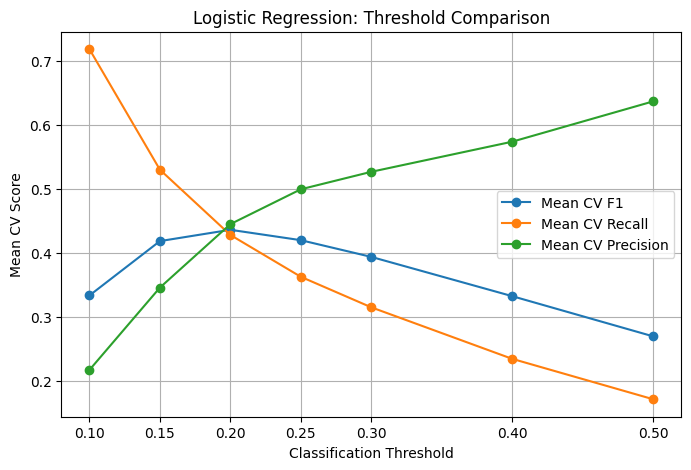

Maximum F1 threshold: 0.2
Confusion matrix:
[[9288  693]
 [ 728  594]]
Maximum Recall threshold: 0.1
Confusion matrix:
[[6588 3393]
 [ 362  960]]

Model: LDA
F1-optimal threshold: 0.15 Mean CV F1: 0.43260314161189345
Recall-optimal threshold: 0.1 Mean CV Recall: 0.5099712490140702


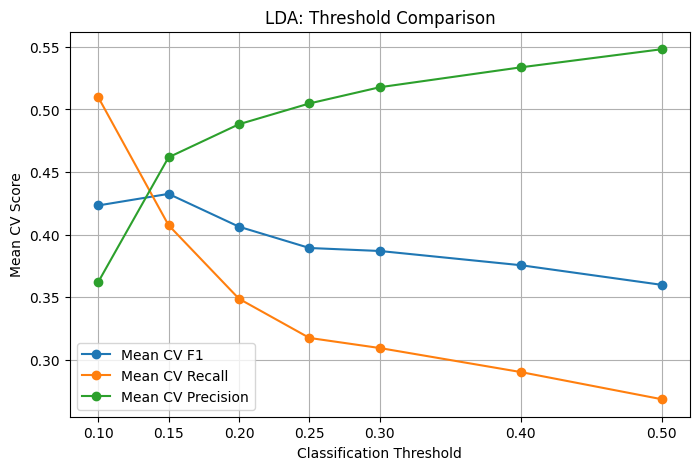

Maximum F1 threshold: 0.15
Confusion matrix:
[[9378  603]
 [ 753  569]]
Maximum Recall threshold: 0.1
Confusion matrix:
[[8803 1178]
 [ 638  684]]

Model: QDA
F1-optimal threshold: 0.25 Mean CV F1: 0.4029153232006755
Recall-optimal threshold: 0.1 Mean CV Recall: 0.5528280283947791


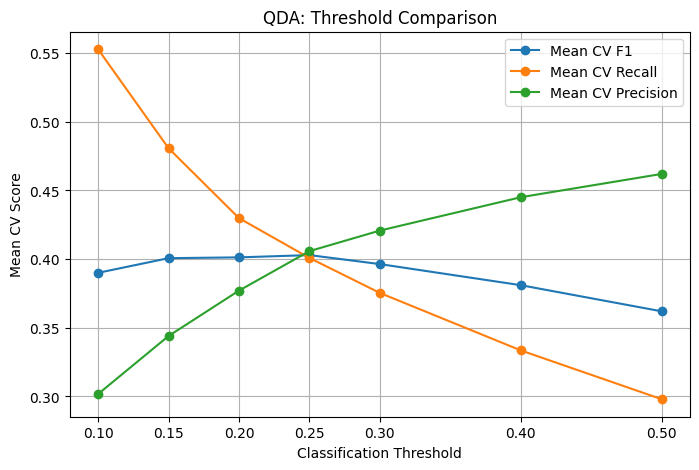

Maximum F1 threshold: 0.25
Confusion matrix:
[[9207  774]
 [ 786  536]]
Maximum Recall threshold: 0.1
Confusion matrix:
[[8276 1705]
 [ 554  768]]

Model: KNN
F1-optimal threshold: 0.1 Mean CV F1: 0.31958844801416164
Recall-optimal threshold: 0.1 Mean CV Recall: 0.5096958247462026


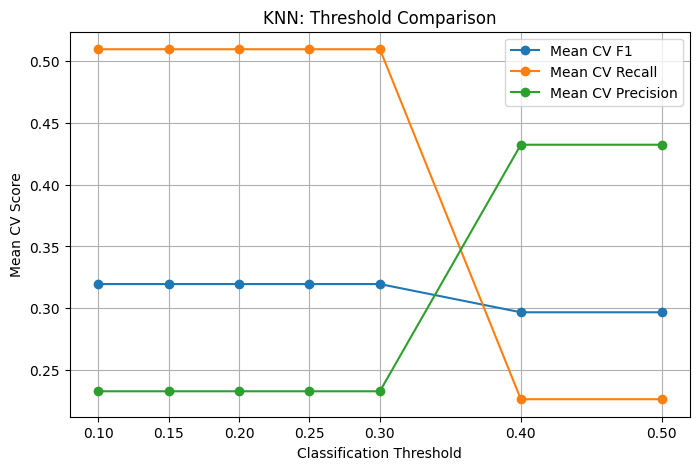

Maximum F1 threshold: 0.1
Confusion matrix:
[[7805 2176]
 [ 625  697]]
Maximum Recall threshold: 0.1
Confusion matrix:
[[7805 2176]
 [ 625  697]]

Final Model Comparison (Test Set):
              Model      Selection  Threshold  Mean CV F1  Mean CV Recall  ROC-AUC     F1  Accuracy  Specificity  Recall  Precision  False Negatives  False Positives
Logistic Regression     Maximum F1       0.20      0.4359          0.4278   0.7734 0.4553    0.8743       0.9306  0.4493     0.4615              728              693
Logistic Regression Maximum Recall       0.10      0.3334          0.7177   0.7734 0.3383    0.6678       0.6601  0.7262     0.2205              362             3393
                LDA     Maximum F1       0.15      0.4326          0.4076   0.7702 0.4563    0.8800       0.9396  0.4304     0.4855              753              603
                LDA Maximum Recall       0.10      0.4234          0.5100   0.7702 0.4296    0.8393       0.8820  0.5174     0.3673              638      

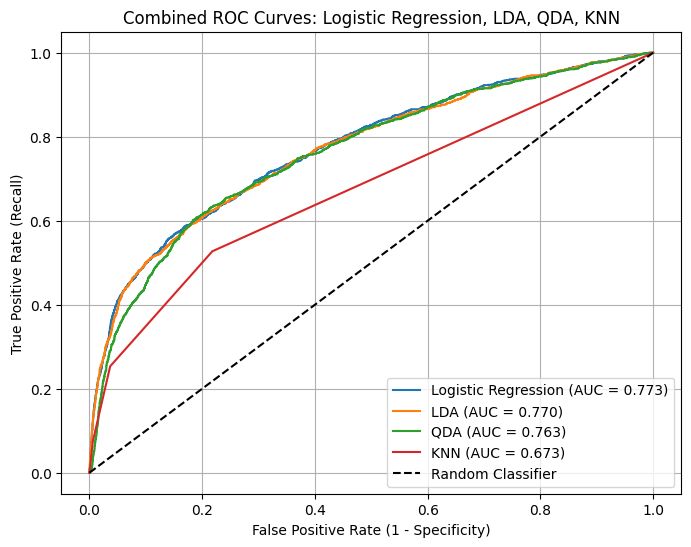

In [8]:
# F1 and Recall threshold evaluation: 10-fold stratified CV on training data only
# Each model is fitted once per fold; each fitted model is evaluated at all thresholds.
models = {
    "Logistic Regression": logreg,
    "LDA": lda,
    "QDA": qda,
    "KNN": knn
}
thresholds = [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]
results = []

for model_name, model in models.items():
    fold_f1 = [[] for threshold in thresholds]
    fold_recall = [[] for threshold in thresholds]
    fold_precision = [[] for threshold in thresholds]

    for train_index, val_index in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_index]
        X_fold_val = X_train.iloc[val_index]
        y_fold_train = y_train.iloc[train_index]
        y_fold_val = y_train.iloc[val_index]

        model.fit(X_fold_train, y_fold_train)
        probabilities = model.predict_proba(X_fold_val)[:, 1]

        for i in range(len(thresholds)):
            predictions = (probabilities >= thresholds[i]).astype(int)
            fold_f1[i].append(f1_score(y_fold_val, predictions, zero_division=0))
            fold_recall[i].append(recall_score(y_fold_val, predictions, zero_division=0))
            fold_precision[i].append(precision_score(y_fold_val, predictions, zero_division=0))

    mean_f1 = [sum(scores) / len(scores) for scores in fold_f1]
    mean_recall = [sum(scores) / len(scores) for scores in fold_recall]
    mean_precision = [sum(scores) / len(scores) for scores in fold_precision]

    best_f1_index = mean_f1.index(max(mean_f1))
    best_recall_index = mean_recall.index(max(mean_recall))

    print("\nModel:", model_name)
    print("F1-optimal threshold:", thresholds[best_f1_index],
          "Mean CV F1:", mean_f1[best_f1_index])
    print("Recall-optimal threshold:", thresholds[best_recall_index],
          "Mean CV Recall:", mean_recall[best_recall_index])

    # Plot CV performance versus threshold for this model
    plt.figure(figsize=(8, 5))
    plt.plot(thresholds, mean_f1, marker='o', label='Mean CV F1')
    plt.plot(thresholds, mean_recall, marker='o', label='Mean CV Recall')
    plt.plot(thresholds, mean_precision, marker='o', label='Mean CV Precision')
    plt.xlabel('Classification Threshold')
    plt.ylabel('Mean CV Score')
    plt.title(model_name + ': Threshold Comparison')
    plt.xticks(thresholds)
    plt.grid(True)
    plt.legend()
    plt.show()

    # Train final model on all training data, without using the test data to select thresholds
    model.fit(X_train, y_train)
    test_probabilities = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, test_probabilities)

    # Evaluate BOTH threshold choices on the held-out test set
    for criterion, index in [('Maximum F1', best_f1_index),
                             ('Maximum Recall', best_recall_index)]:
        chosen_threshold = thresholds[index]
        test_predictions = (test_probabilities >= chosen_threshold).astype(int)
        cm = confusion_matrix(y_test, test_predictions)
        tn, fp, fn, tp = cm.ravel()
        specificity = tn / (tn + fp)

        results.append({
            'Model': model_name,
            'Selection': criterion,
            'Threshold': chosen_threshold,
            'Mean CV F1': mean_f1[index],
            'Mean CV Recall': mean_recall[index],
            'ROC-AUC': auc,
            'F1': f1_score(y_test, test_predictions, zero_division=0),
            'Accuracy': accuracy_score(y_test, test_predictions),
            'Specificity': specificity,
            'Recall': recall_score(y_test, test_predictions, zero_division=0),
            'Precision': precision_score(y_test, test_predictions, zero_division=0),
            'False Negatives': fn,
            'False Positives': fp
        })
        print(criterion, 'threshold:', chosen_threshold)
        print('Confusion matrix:')
        print(cm)

# Comparison table: two threshold-selection strategies for each of four models
results_df = pd.DataFrame(results)
print('\nFinal Model Comparison (Test Set):')
print(results_df.round(4).to_string(index=False))

# Combined ROC curves: one curve per fitted model, independent of chosen threshold
plt.figure(figsize=(8, 6))
for model_name, model in models.items():
    # The final models were fitted on all training data above
    probabilities = model.predict_proba(X_test)[:, 1]
    fpr, tpr, roc_thresholds = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Combined ROC Curves: Logistic Regression, LDA, QDA, KNN')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Part 1: Understanding Your Problem
#1. Each row represents one bank marketing contact. The response variable is y. The possible classes are "yes" and "no", representing whether the customer subscribed to the bank's term deposit product.
#2. The 14 predictors used for classification include: age, balance, campaign, previous, days_since_contact, job, marital, education, default, housing, loan, contact, month, and poutcome. The days_since_contact variable was created from pdays. Duration was excluded because call duration would not be known before the marketing call was completed.
#3. For each class in the response variable, there are 39,922 non-subscribers and 5,289 subscribers. The dataset is highly imbalanced, with approximately 88.3% non-subscribers and 11.7% subscribers, which may influence models to predict no more frequently.
#4. A false positive occurs when the model predicts a subscriber who does not actually subscribe. A false negative occurs when the model predicts a non-subscriber who actually subscribes.
#5. I would be more concerned about whichever classification error results in the greatest financial loss for the bank. False positives would lead to unnecessary marketing expenses, while false negatives would result in missed opportunities to acquire subscribers. Therefore, the relative importance of these errors depends on the cost of contacting customers and the expected financial benefit of successful subscriptions. Since the dataset does not provide this financial information, I cannot definitively determine which error is more costly. However, if contacting customers is relatively inexpensive compared to acquiring a subscriber, I would prioritize reducing false negatives.


#Part 2: Explore and Prepare the Data - Section Referenced (EDA, Data Cleaning, and Feature Engineering)

#1. Occupation seems to have differing subscription rates, with blue-collar workers having relatively low subscription rates and students having relatively high rates. Account balance also appears to vary across age groups. Previous campaign success seems to be positively associated with current subscription status. These relationships suggest associations but do not necessarily establish causation.
#2. The dataset does not contain missing values and no rows are exact duplicates. However, this does not necessarily mean that each customer appears only once, since there are no unique customer identifiers.
#3. The categorical predictors that need to be encoded before modeling include: job, marital, education, default, housing, loan, contact, month, and poutcome. OneHotEncoder was used to encode these variables.
#4. 10-fold stratified cross-validation was used because the dataset is relatively large and the response variable is imbalanced. Stratification maintains approximately the same proportions of subscribers and non-subscribers in each fold. Cross-validation was performed on the training dataset.
#5. Numeric predictors with different scales were standardized using StandardScaler, which transforms variables to have approximately zero mean and unit standard deviation. This is especially important for KNN because distances between observations are used. The numeric predictors include: age, balance, campaign, previous, and days_since_contact.


#Part 3: Build Your Classifiers - Section Referenced (Models)

#1. I trained four classification models: Logistic Regression, Linear Discriminant Analysis (LDA), Quadratic Discriminant Analysis (QDA), and K-Nearest Neighbors (KNN).
#2. After comparing the four models using 10-fold stratified cross-validation, Logistic Regression had the highest mean cross-validation F1 score of 0.4359 at a threshold of 0.20. LDA was close behind with a mean CV F1 of 0.4326 at a threshold of 0.15.
#3. K-neighbors of 3 was still the best for KNN after increasing the number of predictors from 11 to 14.
#4. I also evaluated thresholds that maximize recall to compare the tradeoff between identifying more subscribers and incorrectly predicting non-subscribers as subscribers.


#Part 4: Model Evaluation

#1. I evaluated the models using accuracy, precision, recall, specificity, F1 score, confusion matrices, and ROC-AUC.
#2. Logistic Regression at a threshold of 0.20 achieved a test F1 of 0.4553, accuracy of 87.43%, precision of 46.15%, recall of 44.93%, specificity of 93.06%, and ROC-AUC of 0.7734.
#3. LDA achieved a slightly higher test F1 score of 0.4563, but Logistic Regression had the highest mean cross-validation F1 and ROC-AUC.
#4. I chose Logistic Regression at a threshold of 0.20 because it had the highest mean cross-validation F1 score and the highest ROC-AUC. This suggests that it provides a reasonable balance between identifying subscribers and limiting false positives.


#Part 5: Reflect

#1. Initially, I focused on F1 because I did not know the relative costs of false positives and false negatives. F1 balances precision and recall, making it useful when both are important.
#2. However, contacting multiple potential subscribers may cost less than missing one customer who would have subscribed. Therefore, I also evaluated thresholds that maximize recall.
#3. For Logistic Regression, lowering the threshold from 0.20 to 0.10 increased recall from 44.93% to 72.62%. This reduced false negatives from 728 to 362, allowing the model to identify 366 additional subscribers.
#4. However, false positives increased from 693 to 3,393, while accuracy decreased from 87.43% to 66.78% and precision decreased from 46.15% to 22.05%.
#5. Since maximizing recall resulted in substantially more false positives and lower precision, I decided to retain the F1-optimized threshold of 0.20. However, a lower threshold may be preferable if the bank determines that missing subscribers is significantly more costly than contacting non-subscribers.


#Part 6: ROC and AUC - Last Chart Compares ROC-AUC

#1. ROC stands for Receiver Operating Characteristic, and AUC stands for Area Under the Curve. The ROC curve plots the true positive rate (recall) against the false positive rate (1 - specificity) across different classification thresholds.
#2. ROC-AUC measures how well a model distinguishes between subscribers and non-subscribers across different thresholds. A value of 0.5 indicates performance equivalent to random ranking, while a value of 1.0 indicates perfect discrimination.
#3. Logistic Regression had the highest ROC-AUC of 0.7734, followed by LDA at 0.7702, QDA at 0.7630, and KNN at 0.6732.
#4. The combined ROC graph compares all four models. Logistic Regression performed slightly better than LDA and QDA, while KNN had the lowest ROC-AUC.
#5. Changing the classification threshold affects accuracy, precision, recall, specificity, and F1, but does not change ROC-AUC because ROC-AUC evaluates performance across thresholds.


#Part 7: Final Analysis

#1. The most important differences in performance between the four classifiers were their ability to identify actual subscribers while limiting false positives. Logistic Regression had the highest mean cross-validation F1 and ROC-AUC, while LDA had a marginally higher test F1. QDA performed somewhat worse, and KNN had the lowest F1 and ROC-AUC.
#2. I would deploy Logistic Regression at a threshold of 0.20 because it had the highest mean cross-validation F1 score of 0.4359 and ROC-AUC of 0.7734. Its test F1 of 0.4553 was also very close to LDA's test F1 of 0.4563.
#3. Although lowering the threshold to 0.10 increased recall substantially, it also increased false positives and reduced precision and accuracy. Therefore, I believe a threshold of 0.20 provides a more balanced approach when the financial costs of classification errors are unknown.
#4. A major limitation of this analysis is class imbalance. There are significantly more non-subscribers than subscribers, which may influence models to favor predicting no. This also makes accuracy potentially misleading because a model could achieve high accuracy by predicting the majority class.
#5. Another limitation is that the dataset does not provide the financial costs of contacting customers or the expected revenue from acquiring subscribers. This information would help determine whether precision, recall, F1, or another evaluation measure should be prioritized.
#6. Finally, the models identify predictive associations rather than causal relationships. Additional validation using new customer data would be necessary before deploying the model in an actual marketing campaign.